In [74]:
import statistics
from pyecore.resources import ResourceSet, URI
import os
import ast
import numpy as np
from pathlib import Path
from typing import Callable
import matplotlib.pyplot as plt


fontsz = 16
import re


def numeric_dir_key_direct(path: str) -> tuple:
    """
    Extract all numbers from a directory name for multi-level numeric sorting.
    Numbers are typically prefixed by "_" or "-".
    
    Sorts ascendingly by first number, then by second number (if first is equal), etc.
    E.g., "1_ab" < "1_2" < "1_10" < "41_d" < "41-5" < "412_e"
    
    Returns:
        A tuple of integers for sorting. Non-numeric items sort last.
    """
    name = os.path.basename(path)
    # Find all numbers, optionally prefixed by "_" or "-"
    numbers = re.findall(r'(?:^|[_-])(\d+)', name)
    
    if numbers:
        # Convert to integers for proper numeric sorting
        return tuple(int(n) for n in numbers)
    else:
        # Items without numbers sort last
        return (float("inf"),)

def compute_worst_case_scrum_fitness(metamodel_path, instance_path):
    """
    Concise version of worst-case fitness computation.
    """
    rset = ResourceSet()
    
    # Load the metamodel
    metamodel_resource = rset.get_resource(URI(metamodel_path))
    metamodel_root = metamodel_resource.contents[0]
    
    # Register the metamodel package
    rset.metamodel_registry[metamodel_root.nsURI] = metamodel_root
    
    # Load the instance model
    instance_resource = rset.get_resource(URI(instance_path))
    model = instance_resource.contents[0]
    # Calculate total effort across all items
    total_effort = sum(
        float(item.Effort)
        for item in model.backlog.workitems
    )
    
    # Worst case: [total_effort, 0, 0, ..., 0] with minSprints total values
    min_sprints = model.minSprints
    worst_case_distribution = [total_effort] + [0.0] * (min_sprints - 1)

    wc_stdev_effort = statistics.stdev(worst_case_distribution) if min_sprints >= 2 else 0.0

    def compute_stakeholder_worst_case_deviation(stakeholder):
        # Calculate total importance for this stakeholder
        total_importance = sum(
            float(item.Importance)
            for item in model.backlog.workitems
            if item.stakeholder == stakeholder
        )
        
    
        
        # Worst case: [total_importance, 0, 0, ..., 0]
        worst_case_values = [float(total_importance)] + [0.0] * (min_sprints - 1)
        
        return statistics.stdev(worst_case_values) if min_sprints >= 2 else 0.0
    
    # Sum deviations across all stakeholders
    stakeholder_importance_deviations = sum(
        compute_stakeholder_worst_case_deviation(stakeholder)
        for stakeholder in model.stakeholders
    )

    return wc_stdev_effort + stakeholder_importance_deviations

def compute_stack_load_stddev(metamodel_path, instance_path):
    """
    Computes the standard deviation of load amounts across all stacks in a model.
    
    Args:
        metamodel_path: Path to the .ecore metamodel file
        instance_path: Path to the .xmi instance file
    
    Returns:
        float: Standard deviation of stack loads
    """
    # Create a resource set
    rset = ResourceSet()
    
    # Load the metamodel
    metamodel_resource = rset.get_resource(URI(metamodel_path))
    metamodel_root = metamodel_resource.contents[0]
    
    # Register the metamodel package
    rset.metamodel_registry[metamodel_root.nsURI] = metamodel_root
    
    # Load the instance model
    instance_resource = rset.get_resource(URI(instance_path))
    model_root = instance_resource.contents[0]
    
    # Collect load amounts from all stacks
    load_amounts = []
    for stack in model_root.stacks:
        load_amounts.append(stack.load)
    
    # Compute standard deviation
    if len(load_amounts) < 2:
        return 0.0  # Standard deviation requires at least 2 values
    
    stddev = statistics.stdev(load_amounts)
    
    return stddev

In [75]:
def plot_train_test_scatter(train_performances, test_performances, 
                           title='Mean rel. improvement (std) per ML model (N=30)',
                           xlabel='Training instances',
                           ylabel='Test instances',
                           xlim=(0.7, 0.85),
                           ylim=(0.7, 0.85),
                           figsize=(4, 4),
                           output_path=None, label_offset=0.01 , # 'ellipse', 'error_bars', 'cross', 'box', or None
                           dispersion_alpha=0.2,
                           return_gap_stats=False):
    """
    Create a scatter plot comparing training vs test performance across models.
    
    Parameters:
    -----------
    train_performances : list of dict
        List of dictionaries, each containing model performances on a training instance
    test_performances : list of dict
        List of dictionaries, each containing model performances on a test instance
    title : str, optional
        Plot title
    xlabel : str, optional
        X-axis label
    ylabel : str, optional
        Y-axis label
    xlim : tuple, optional
        X-axis limits (min, max)
    ylim : tuple, optional
        Y-axis limits (min, max)
    figsize : tuple, optional
        Figure size (width, height)
    output_path : str, optional
        If provided, save the plot to this path (e.g., '../plots/output.pdf')
    
    Returns:
    --------
    fig, ax : matplotlib figure and axis objects
    """
    from matplotlib.patches import Ellipse

    # Get model names
    models = list(train_performances[0].keys())
    
    # Compute per-model mean relative improvement over training instances
    train_means = []
    test_means = []
    seed_labels = []
    train_stds = []
    test_stds = []

    for model in models:
        # Average over training instances
        train_vals = [d[model] for d in train_performances]
        train_mean = np.mean(train_vals)
        train_means.append(train_mean)
        train_std = np.std(train_vals)
        train_stds.append(train_std)
        
        # Average over test instances
        test_vals = [d[model] for d in test_performances]
        test_mean = np.mean(test_vals)
        test_std = np.std(test_vals)
        test_stds.append(test_std)
        test_means.append(test_mean)

        # Extract seed number from model key (format: "something--<seed_number>")
        if '--' in model:
            seed = model.split('--')[-1]
        else:
            seed = model  # Fallback if no "--" found
        seed_labels.append(f"{model.split('-')[0]}-{seed}")
    
    # Generalization gap stats (train vs test)
    per_model_gaps = [t - s for t, s in zip(train_means, test_means)]
    mean_train = float(np.mean(train_means)) if train_means else 0.0
    mean_test = float(np.mean(test_means)) if test_means else 0.0
    gap_mean = float(np.mean(per_model_gaps)) if per_model_gaps else 0.0
    gap_std = float(np.std(per_model_gaps)) if per_model_gaps else 0.0
    gap_stats = {
        "mean_train": mean_train,
        "mean_test": mean_test,
        "gap_mean": gap_mean,
        "gap_std": gap_std,
    }
    
    # Create scatter plot
    fig, ax = plt.subplots(figsize=figsize)


    # Cross-shaped error bars (more minimalist)
    for x, y, x_std, y_std in zip(train_means, test_means, train_stds, test_stds):
        # Horizontal bar
        ax.plot([x-x_std, x+x_std], [y, y], 
                color='gray', linewidth=1, alpha=dispersion_alpha*2)
        # Vertical bar
        ax.plot([x, x], [y-y_std, y+y_std], 
                color='gray', linewidth=1, alpha=dispersion_alpha*2)
    

    
    # Plot points (if not using gradient color scheme)
    ax.scatter(train_means, test_means, color='black', s=25, alpha=0.95, zorder=3)

    # Diagonal line
    lims = [0, max(max(train_means), max(test_means)) * 1.1]
    ax.plot(lims, lims, '--', color='gray', linewidth=1, zorder=2)
    
    # Set limits
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    
    # Axis labels
    ax.set_xlabel(xlabel, fontsize=fontsz)
    ax.set_ylabel(ylabel, fontsize=fontsz)
    ax.set_title(title, fontsize=fontsz, fontweight='bold')
    
    # Minimalist design
    ax.tick_params(labelsize=fontsz)
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    plt.tight_layout()
    
    # Save if output path provided
    if output_path:
        plt.savefig(output_path, format='pdf', dpi=300, bbox_inches='tight', 
                   pad_inches=0.02, transparent=False)
    
    plt.show()
    
    if return_gap_stats:
        return fig, ax, gap_stats
    return fig, ax

def read_solution_vectors(directory: str) -> dict[str, list[list[float]]]:
    """
    Read solution vectors from all subdirectories containing 'nn-solutions.txt'.
    
    Args:
        directory: Path to the parent directory containing subdirectories
        
    Returns:
        Dictionary mapping subdirectory name to list of solution vectors
    """
    solutions_by_run = {}
    base_path = Path(directory)
    
    for subdir in base_path.iterdir():
        if subdir.is_dir():
            solutions_file = subdir / "nn-solutions.txt"
            if solutions_file.exists():
                vectors = []
                with open(solutions_file, 'r') as f:
                    for line in f:
                        line = line.strip()
                        if line:
                            vector = ast.literal_eval(line)
                            vectors.append(vector)
                solutions_by_run[subdir.name] = vectors
    
    return solutions_by_run

def extract_values(
    solution_vectors: list[list[float]], 
    dimension: int = 0
) -> list[float]:
    """Extract values from a specific dimension of solution vectors."""
    return [vec[dimension] for vec in solution_vectors]


def combine_dimensions(
    solution_vectors: list[list[float]], 
    dimensions: list[int], 
    combiner: Callable[[list[float]], float] = sum
) -> list[float]:
    """
    Combine multiple dimensions of solution vectors using a combiner function.
    
    Args:
        solution_vectors: List of solution vectors
        dimensions: List of dimension indices to combine
        combiner: Function to combine values (default: sum)
        
    Returns:
        List of combined values, one per solution vector
    """
    combined = []
    for vec in solution_vectors:
        values = [vec[d] for d in dimensions]
        combined.append(combiner(values))
    return combined


def get_best_value(values: list[float], minimize: bool = True) -> float:
    """
    Find the best value from a list.
    
    Args:
        values: List of values
        minimize: If True, find minimum; if False, find maximum
        
    Returns:
        The best value
    """
    if not values:
        raise ValueError("No values provided")
    return min(values) if minimize else max(values)

In [76]:
def compute_best_per_run(
    solutions_by_run: dict[str, list[list[float]]], 
    value_extractor: Callable[[list[list[float]]], list[float]],
    minimize: bool = True
) -> dict[str, float]:
    """
    Compute best value per run using a custom value extractor.
    
    Args:
        solutions_by_run: Dictionary mapping run name to solution vectors
        value_extractor: Function that takes solution vectors and returns values to optimize
        minimize: If True, find minimum; if False, find maximum
        
    Returns:
        Dictionary mapping run name to best value
    """
    best_values = {}
    for run_name, vectors in solutions_by_run.items():
        values = value_extractor(vectors)
        best_values[run_name] = get_best_value(values, minimize)
    return best_values

def normalize_worst_best(value: float, worst: float, best: float) -> float:
    """
    Map a raw objective value onto [0, 1] for minimization problems.

    Returns 0 at ``worst``, 1 at ``best``, and values in between proportionally.
    """
    if worst == best:
        raise ValueError("Worst and best values must be different")
    return (worst - value) / (worst - best)


def relative_improvement_vs_baseline(baseline: float, value: float) -> float:
    """
    Fraction of the baseline removed by ``value`` (ideal objective is 0).

    Equivalent to ``normalize_worst_best(value, worst=baseline, best=0)``.
    """
    return normalize_worst_best(value, worst=baseline, best=0.0)


def relative_improvement_normalized(
    baseline: float, value: float, worst: float, best: float
) -> float:
    """
    Relative improvement of ``value`` over ``baseline`` after both are
    mapped with ``normalize_worst_best``.
    """
    baseline_n = normalize_worst_best(baseline, worst, best)
    value_n = normalize_worst_best(value, worst, best)

    if baseline_n == 0:
        raise ValueError("Baseline is at worst-case; relative improvement undefined")

    return (value_n - baseline_n) / baseline_n

In [77]:
SOLUTIONS_PATH = '../rq3-generalization/solutions/'
METAMODEL_PATH = '../../GNN-MT/data/'
MODELS_PATH = '../../models/datasets/'

#### SLB

In [78]:
train_models_performances = []
rel_improvements = []
directory = sorted(
    [f.path for f in os.scandir(SOLUTIONS_PATH + 'slb/train-set-.25-.50/single') if f.is_dir()],
    key=numeric_dir_key_direct
 )
model_names = [os.path.basename(d) for d in directory]
initial_stds = [compute_stack_load_stddev(METAMODEL_PATH + 'stack.ecore', MODELS_PATH + 'slb/train-N30-25.-50./' + os.path.basename(m) + ".xmi") for m in model_names]
# Resort directory, model_names, and initial_stds based on initial_stds in ascending order
sorted_indices = sorted(range(len(initial_stds)), key=lambda i: initial_stds[i])
directory = [directory[i] for i in sorted_indices]
model_names = [model_names[i] for i in sorted_indices]
initial_stds = [initial_stds[i] for i in sorted_indices]
# Print the names and initial_stds for verification
#for name, std in zip(model_names, initial_stds):
#    print(f"{name}: {std:.4f}")


for idx, d in enumerate(directory):
    solutions_by_run = read_solution_vectors(d)

    best_per_run = compute_best_per_run(
        solutions_by_run, 
        value_extractor=lambda vecs: extract_values(vecs, dimension=0),
        minimize=True
    )
    train_models_performances.append({k: relative_improvement_vs_baseline(initial_stds[idx], v) for k, v in best_per_run.items()})

    # Example usage

test_models_performances = []
rel_improvements = []
directory = sorted(
    [f.path for f in os.scandir(SOLUTIONS_PATH + 'slb/test-set-.25-.50/single') if f.is_dir()],
    key=numeric_dir_key_direct
 )
model_names = [os.path.basename(d) for d in directory]

initial_stds = [compute_stack_load_stddev(METAMODEL_PATH + 'stack.ecore', MODELS_PATH + 'slb/test-N30-25.-50./' + os.path.basename(m) + ".xmi") for m in model_names]


for idx, d in enumerate(directory):
    solutions_by_run = read_solution_vectors(d)

    best_per_run = compute_best_per_run(
        solutions_by_run, 
        value_extractor=lambda vecs: extract_values(vecs, dimension=0),
        minimize=True
    )
    test_models_performances.append({k: relative_improvement_vs_baseline(initial_stds[idx], v) for k, v in best_per_run.items()})





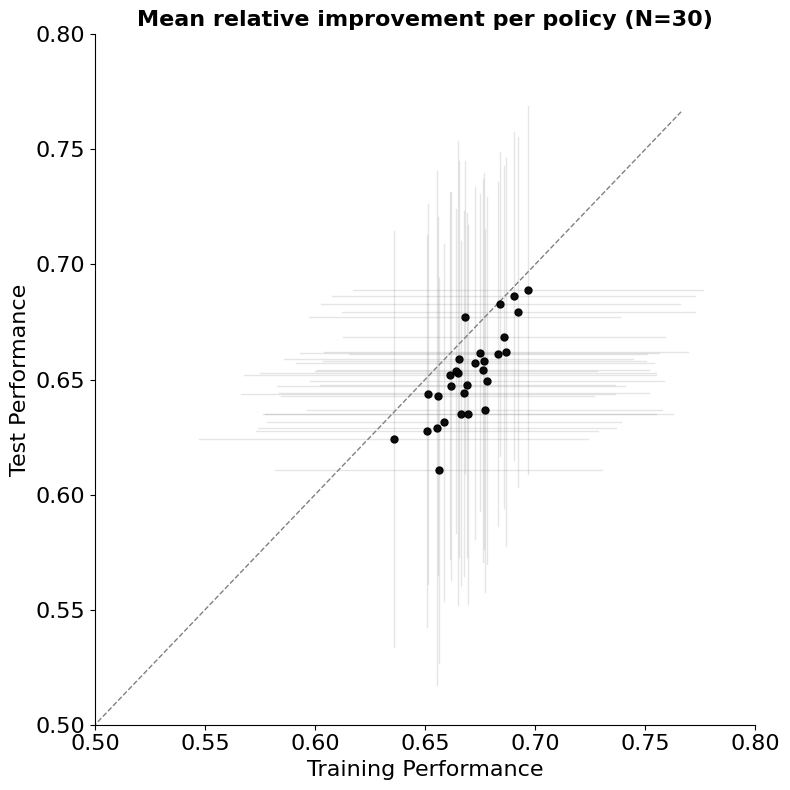

{'mean_train': 0.6699010789826494, 'mean_test': 0.6519251561569989, 'gap_mean': 0.017975922825650463, 'gap_std': 0.011548380949164022}


In [79]:
fig, ax, gap_stats = plot_train_test_scatter(
    train_models_performances, 
    test_models_performances,
    xlabel='Training Performance',
    ylabel='Test Performance',
    title='Mean relative improvement per policy (N=30)',
       xlim=(0.5, 0.8),
    ylim=(0.5, 0.8),
    figsize=(8, 8),
    output_path=None,return_gap_stats=True, dispersion_alpha=.1,
)
print(gap_stats)


#### CRA

In [80]:
train_models_performances = []
rel_improvements = []
directory = sorted(
    [f.path for f in os.scandir(SOLUTIONS_PATH + 'cra/train-d0.15-.25/single') if f.is_dir()],
    key=numeric_dir_key_direct
 )
model_names = [os.path.basename(d) for d in directory]
# Worst case is 1 (cohesion=0, coupling=1), best case is -1 (cohesion=1, coupling=0)

for idx, d in enumerate(directory):
    solutions_by_run = read_solution_vectors(d)
    
    best_per_run = compute_best_per_run(
        solutions_by_run, 
    value_extractor=lambda vecs: combine_dimensions(vecs, dimensions=[0, 1], combiner=sum),
        minimize=True
    )
    train_models_performances.append({k: normalize_worst_best(v, 1, -1) for k, v in best_per_run.items()})


test_models_performances = []
rel_improvements = []
directory = sorted(
    [f.path for f in os.scandir(SOLUTIONS_PATH + 'cra/test-d0.15-.25/single') if f.is_dir()],
    key=numeric_dir_key_direct
 )
directory_name = [os.path.basename(d) for d in directory]

for idx, d in enumerate(directory):
    solutions_by_run = read_solution_vectors(d)
    best_per_run = compute_best_per_run(
        solutions_by_run, 
    value_extractor=lambda vecs: combine_dimensions(vecs, dimensions=[0, 1], combiner=sum),
        minimize=True
    )
    test_models_performances.append({k: normalize_worst_best(v, 1, -1) for k, v in best_per_run.items()})

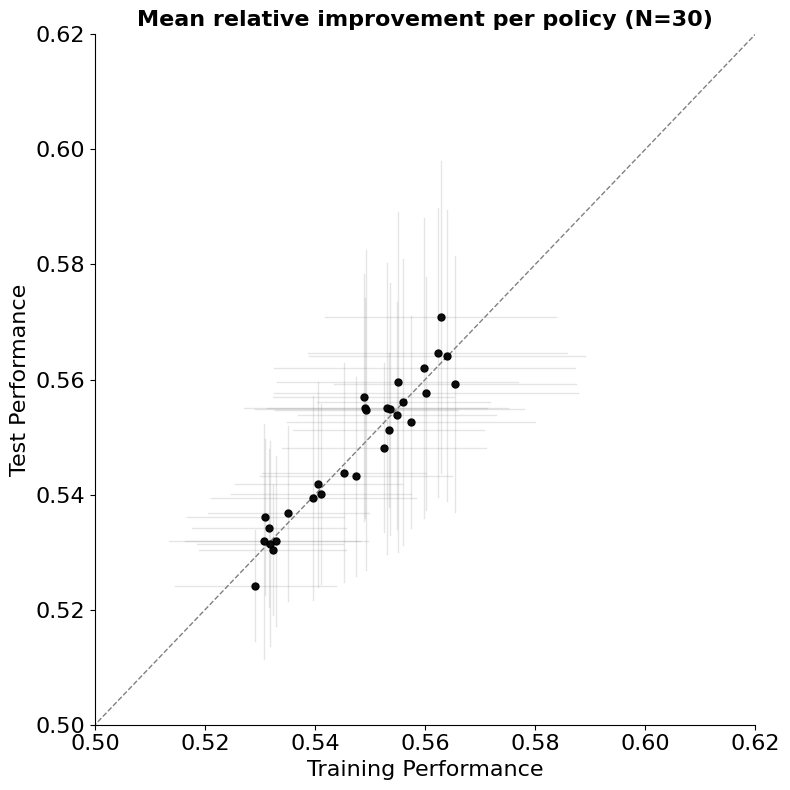

{'mean_train': 0.5475525920799472, 'mean_test': 0.5480534965185981, 'gap_mean': -0.0005009044386508547, 'gap_std': 0.0036794629987036273}


In [81]:
fig, ax, gap_stats = plot_train_test_scatter(
    train_models_performances, 
    test_models_performances,
    xlabel='Training Performance',
    ylabel='Test Performance',
    title='Mean relative improvement per policy (N=30)',
        xlim=(0.5, 0.62),
    ylim=(0.5, 0.62),
    figsize=(8, 8),
    output_path=None, return_gap_stats=True, dispersion_alpha=.1
)
print(gap_stats)

# SP

In [82]:
# Example usage
train_models_performances = []

directory = sorted(
    [f.path for f in os.scandir(SOLUTIONS_PATH + 'sp/training-set-60to120/single') if f.is_dir()],
    key=numeric_dir_key_direct
 )
model_names = [os.path.basename(d) for d in directory]
ref_sp = [compute_worst_case_scrum_fitness(METAMODEL_PATH + "sprintplanning.ecore", MODELS_PATH + "sp/trainingset-60to120/" + os.path.basename(m) + ".xmi") for m in model_names]
best_sp = 0.

for idx, d in enumerate(directory):
    solutions_by_run = read_solution_vectors(d)
    best_per_run = compute_best_per_run(
        solutions_by_run, 
    value_extractor=lambda vecs: combine_dimensions(vecs, dimensions=[0, 1], combiner=sum),
        minimize=True
    )
    train_models_performances.append({k: normalize_worst_best(v, ref_sp[idx], best_sp) for k, v in best_per_run.items()})


test_models_performances = []

directory = sorted(
    [f.path for f in os.scandir(SOLUTIONS_PATH + 'sp/test-set-60to120/single') if f.is_dir()],
    key=numeric_dir_key_direct
 )
model_names = [os.path.basename(d) for d in directory]
#compute_stack_load_stddev("../data/stack.ecore", "/home/martin/Desktop/projects/jku/momot-DL-2025/momot-ml/momot/examples/at.ac.tuwien.big.momot.examples.stack/model/train-N30-25.-50./10_stacks-36.6.xmi")

ref_sp = [compute_worst_case_scrum_fitness(METAMODEL_PATH + "sprintplanning.ecore", MODELS_PATH + "sp/testset-60to120/" + os.path.basename(m) + ".xmi") for m in model_names]
best_sp = 0.

for idx, d in enumerate(directory):
    solutions_by_run = read_solution_vectors(d)
    best_per_run = compute_best_per_run(
        solutions_by_run, 
    value_extractor=lambda vecs: combine_dimensions(vecs, dimensions=[0, 1], combiner=sum),
        minimize=True
    )
    test_models_performances.append({k: normalize_worst_best(v, ref_sp[idx], best_sp) for k, v in best_per_run.items()})

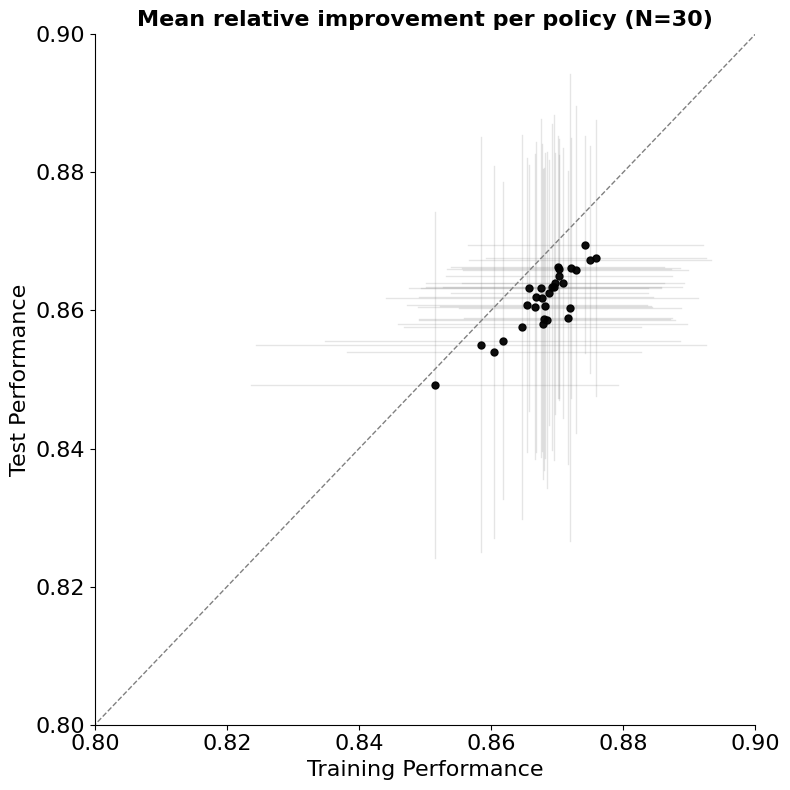

{'mean_train': 0.8680577468721528, 'mean_test': 0.8616535923251741, 'gap_mean': 0.006404154546978898, 'gap_std': 0.002396001650911388}


In [83]:
fig, ax, gap_stats = plot_train_test_scatter(
    train_models_performances, 
    test_models_performances,
    xlabel='Training Performance',
    ylabel='Test Performance',
    title='Mean relative improvement per policy (N=30)',
    xlim=(0.8, 0.9),
    ylim=(0.8, 0.9),
    figsize=(8, 8),dispersion_alpha=.1, return_gap_stats=True,
    output_path=None
)
print(gap_stats)
